# Tutorial 9: 4D-Var, Part 1. The Cost Function and the Linear Case

*Part 1 of 5 of the 4D-Var module.  Next: [Tutorial 10, tangent-linear and adjoint](10_4DVar_tangent_linear_and_adjoint.ipynb).*

**Question.** We have a model forecast (the *background*) and some noisy measurements. How do we combine them into the best estimate of the state, and what is "best"?

Weather forecasting does this every few hours, and the method it uses is **4D-Var**. This first notebook builds the idea in the simplest possible setting, a *linear* model with Gaussian errors, where everything can be checked against exact formulas. Parts 2 to 5 then deal with the nonlinear, chaotic case.

**You will learn**

- the 4D-Var cost function and where its two terms come from;
- that for linear problems it is the Tikhonov least squares of Tutorial 4 with a statistical meaning;
- the Kalman gain formula, and why 4D-Var and the Kalman filter agree in the linear-Gaussian case (the link to a later tutorial);
- how information from an observed variable reaches an unobserved one through the dynamics.

~20 minutes. NumPy and Matplotlib only.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True})

## 1. Two thermometers

A room is predicted to be $x_b=20^\circ$C (error std $\sigma_b=2$). A thermometer reads $y=23^\circ$C (error std $\sigma_o=1$). Assuming independent Gaussian errors, the most probable temperature minimises

$$J(x)=\frac{(x-x_b)^2}{2\sigma_b^2}+\frac{(y-x)^2}{2\sigma_o^2}.$$

This is $-\log$ of (prior $\times$ likelihood), so the minimiser is the *maximum a posteriori* estimate. Setting $J'=0$:

$$x_a=x_b+K\,(y-x_b),\qquad K=\frac{\sigma_b^2}{\sigma_b^2+\sigma_o^2},\qquad \frac1{\sigma_a^2}=\frac1{\sigma_b^2}+\frac1{\sigma_o^2}.$$

The *innovation* $y-x_b$ is the surprise, and the gain $K$ says how much of it to believe. The analysis is more certain than either source.

K = 0.80,  x_a = 22.40,  sigma_a = 0.89  (sigma_b = 2.0, sigma_o = 1.0)


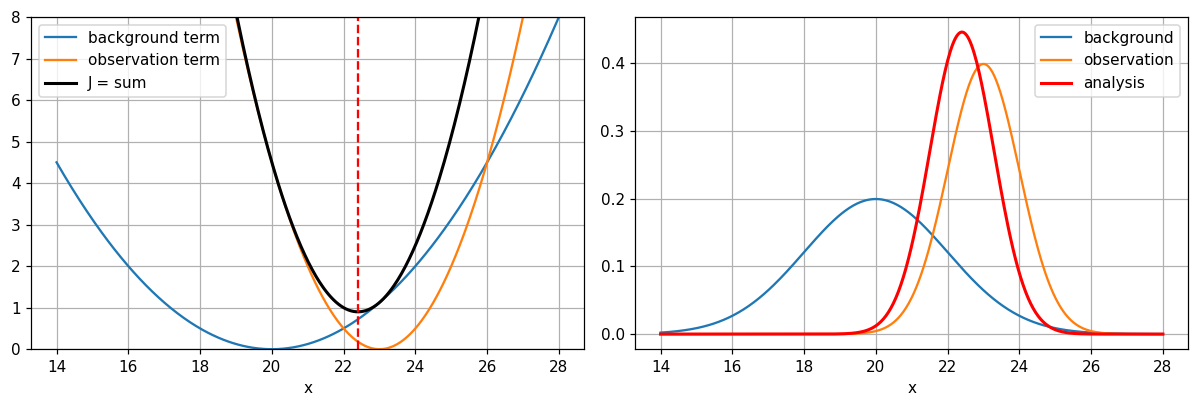

In [2]:
xb, sb, y, so = 20.0, 2.0, 23.0, 1.0
K = sb**2 / (sb**2 + so**2)
xa = xb + K*(y - xb)
sa = np.sqrt(1/(1/sb**2 + 1/so**2))
print(f"K = {K:.2f},  x_a = {xa:.2f},  sigma_a = {sa:.2f}  (sigma_b = {sb}, sigma_o = {so})")

x = np.linspace(14, 28, 400)
J = (x-xb)**2/(2*sb**2) + (y-x)**2/(2*so**2)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(x, (x-xb)**2/(2*sb**2), label="background term")
ax[0].plot(x, (y-x)**2/(2*so**2), label="observation term")
ax[0].plot(x, J, "k", lw=2, label="J = sum")
ax[0].axvline(xa, color="r", ls="--"); ax[0].set_ylim(0, 8); ax[0].set_xlabel("x"); ax[0].legend()
g = lambda m, s: np.exp(-0.5*((x-m)/s)**2)/(s*np.sqrt(2*np.pi))
ax[1].plot(x, g(xb, sb), label="background"); ax[1].plot(x, g(y, so), label="observation")
ax[1].plot(x, g(xa, sa), "r", lw=2, label="analysis"); ax[1].set_xlabel("x"); ax[1].legend()
plt.tight_layout(); plt.show()

The analysis sits closer to the more accurate source (the thermometer) and is sharper than both.

## 2. Many variables: the general linear case

For a state vector $\mathbf x\in\mathbb R^n$, observations $\mathbf y=H\mathbf x+\boldsymbol\varepsilon$ and error covariances $B$ (background) and $R$ (observation):

$$J(\mathbf x)=\tfrac12(\mathbf x-\mathbf x_b)^TB^{-1}(\mathbf x-\mathbf x_b)+\tfrac12(\mathbf y-H\mathbf x)^TR^{-1}(\mathbf y-H\mathbf x).$$

Three equivalent ways to get the minimiser, all checked below:

1. **Kalman gain form:** $\mathbf x_a=\mathbf x_b+K(\mathbf y-H\mathbf x_b)$, $K=BH^T(HBH^T+R)^{-1}$.
2. **Whitened least squares** . Stack $B^{-1/2}(\mathbf x-\mathbf x_b)$ and $R^{-1/2}(H\mathbf x-\mathbf y)$ as one residual and solve with `lstsq`. The background acts as a Tikhonov term whose weight is set by *physics* ($B$), not by an L-curve.
3. **Hessian form:** the analysis covariance is $A=(B^{-1}+H^TR^{-1}H)^{-1}$, the inverse Hessian of $J$.

In [3]:
rng = np.random.default_rng(0)
nx, ny = 4, 2
G = rng.standard_normal((nx, nx)); B = G @ G.T + 0.5*np.eye(nx)      # SPD background covariance
R = np.diag([0.3, 0.5])**2
H = rng.standard_normal((ny, nx))
x_true = rng.standard_normal(nx)
xb = x_true + np.linalg.cholesky(B) @ rng.standard_normal(nx)
y = H @ x_true + np.linalg.cholesky(R) @ rng.standard_normal(ny)

# 1. Kalman gain form
Kg = B @ H.T @ np.linalg.inv(H @ B @ H.T + R)
xa1 = xb + Kg @ (y - H @ xb)

# 2. whitened (stacked) least squares
Lb = np.linalg.cholesky(np.linalg.inv(B)).T          # Lb^T Lb = B^-1
Lr = np.linalg.cholesky(np.linalg.inv(R)).T
Amat = np.vstack([Lb, Lr @ H]); bvec = np.concatenate([Lb @ xb, Lr @ y])
xa2 = np.linalg.lstsq(Amat, bvec, rcond=None)[0]

# 3. Hessian: analysis covariance
Pa_hess = np.linalg.inv(np.linalg.inv(B) + H.T @ np.linalg.inv(R) @ H)
Pa_kal = (np.eye(nx) - Kg @ H) @ B

print("max |x_a(gain) - x_a(lstsq)| =", np.abs(xa1 - xa2).max())
print("max |A(Hessian) - (I-KH)B|   =", np.abs(Pa_hess - Pa_kal).max())
print("trace B =", np.trace(B).round(3), "  trace A =", np.trace(Pa_hess).round(3))

max |x_a(gain) - x_a(lstsq)| = 6.661338147750939e-16
max |A(Hessian) - (I-KH)B|   = 1.8318679906315083e-15
trace B = 15.498   trace A = 2.841


All three agree to round-off, and the trace of $A$ is smaller than the trace of $B$ because the data reduced the uncertainty. This is the strong link to Tutorial 4: 3D-Var (4D-Var without time) *is* Tikhonov least squares with a statistically chosen regularisation.

## 3. Adding time: a linear model over a window

Now the state evolves: $\mathbf x_{k+1}=M\mathbf x_k$. Observations $\mathbf y_k=H\mathbf x_k+\varepsilon_k$ arrive at several times in a window. The only unknown is the **initial** state $\mathbf x_0$, and

$$J(\mathbf x_0)=\tfrac12\|\mathbf x_0-\mathbf x_b\|^2_{B^{-1}}+\tfrac12\sum_{k}\|H M^k\mathbf x_0-\mathbf y_k\|^2_{R^{-1}} .$$

The "4D" is the three space dimensions plus time: the model $M^k$ lets an observation at time $k$ constrain the state at time $0$.

Example: a damped oscillator $(\text{position},\text{velocity})$ where we observe **only the position**.

In [4]:
th = 0.35
M = 0.995*np.array([[np.cos(th), np.sin(th)], [-np.sin(th), np.cos(th)]])   # slowly damped rotation
H = np.array([[1.0, 0.0]])                  # observe position only
R = np.array([[0.2**2]])
B = np.diag([1.0, 1.0])**2
x_true0 = np.array([0.5, 1.0])
xb = np.array([-0.4, 0.2])                  # poor background

def window_solution(nobs, rng):
    # truth trajectory and observations at k = 1..nobs
    xs = [x_true0]
    for _ in range(nobs): xs.append(M @ xs[-1])
    ys = [H @ xs[k] + 0.2*rng.standard_normal(1) for k in range(1, nobs+1)]
    # stacked least squares for x0 (rows: background, then H M^k)
    Binv = np.linalg.inv(B); Rinv = np.linalg.inv(R)
    Lb = np.linalg.cholesky(Binv).T; Lr = np.linalg.cholesky(Rinv).T
    rows = [Lb]; rhs = [Lb @ xb]; Mk = np.eye(2)
    for k in range(1, nobs+1):
        Mk = M @ Mk
        rows.append(Lr @ H @ Mk); rhs.append(Lr @ ys[k-1])
    Amat = np.vstack(rows); b = np.concatenate(rhs)
    x0a = np.linalg.lstsq(Amat, b, rcond=None)[0]
    A = np.linalg.inv(Amat.T @ Amat)         # analysis covariance (inverse Hessian)
    return x0a, A, ys

rng = np.random.default_rng(3)
for nobs in [1, 3, 10, 30]:
    x0a, A, _ = window_solution(nobs, rng)
    print(f"{nobs:3d} obs:  x0_a = {np.round(x0a,3)},  std(pos, vel) = {np.round(np.sqrt(np.diag(A)),3)}")
print("truth        x0   =", x_true0, "   background std = (1, 1)")

  1 obs:  x0_a = [0.981 0.704],  std(pos, vel) = [0.39  0.942]
  3 obs:  x0_a = [0.03 1.25],  std(pos, vel) = [0.264 0.305]
 10 obs:  x0_a = [0.412 0.998],  std(pos, vel) = [0.089 0.095]
 30 obs:  x0_a = [0.495 0.974],  std(pos, vel) = [0.056 0.056]
truth        x0   = [0.5 1. ]    background std = (1, 1)


Only the position is measured, yet the **velocity** uncertainty shrinks as observations accumulate. The model rotates position into velocity, so later position data carry information about the initial velocity. This is the central benefit of 4D-Var over 3D-Var: the dynamics spread information from observed variables to unobserved ones.

## 4. 4D-Var equals the Kalman filter (for linear Gaussian problems)

Run a Kalman filter forward through the same window (predict with $M$, update with each observation). Its final mean must equal the 4D-Var solution propagated to the end of the window, and its final covariance must equal $M^N A M^{NT}$.

In [5]:
def kalman(nobs, ys):
    xm, P = xb.copy(), B.copy()
    for k in range(nobs):
        xm, P = M @ xm, M @ P @ M.T                         # predict (no model error)
        S = H @ P @ H.T + R
        Kk = P @ H.T @ np.linalg.inv(S)
        xm = xm + Kk @ (ys[k] - H @ xm)                      # update
        P = (np.eye(2) - Kk @ H) @ P
    return xm, P

nobs = 10
rng = np.random.default_rng(5)
x0a, A, ys = window_solution(nobs, rng)
xm, P = kalman(nobs, ys)
MN = np.linalg.matrix_power(M, nobs)
print("Kalman mean at T :", xm)
print("M^N x0_a (4D-Var) :", MN @ x0a)
print("max cov difference:", np.abs(P - MN @ A @ MN.T).max())

Kalman mean at T : [-0.65431823 -0.7330788 ]
M^N x0_a (4D-Var) : [-0.65431823 -0.7330788 ]
max cov difference: 3.469446951953614e-18


They agree to round-off. For linear models and Gaussian errors the two are the same estimator in two forms: the filter processes data sequentially and carries a covariance; 4D-Var optimises over the whole window and needs no covariance propagation (only $B$ at the start). That is why 4D-Var scales to models with $10^8$ variables while the full Kalman filter does not.

**For nonlinear chaotic models the equivalence breaks**, $J$ is no longer a quadratic, and we need gradients through the model. That is Part 2.

## Exercises

1. In the two-thermometer example, double $\sigma_o$. How do $K$ and $\sigma_a$ change? What if $\sigma_b\to\infty$?
2. In Section 2, replace $B$ by $\alpha I$ and sweep $\alpha$. Compare with the Tikhonov parameter sweep of Tutorial 4. Which values of $\alpha$ correspond to a very strong prior?
3. In Section 3, observe only the velocity instead. Does position uncertainty also shrink?
4. Set the damping to 1.0 and the rotation angle to $\pi$. The map is then $-I$. Show that the velocity is no longer recoverable from position observations (an *unobservable* case) by looking at the singular values of the stacked matrix.
5. Add model error $Q>0$ to the Kalman filter. Why can 4D-Var as written here not reproduce the filter any more? (Part 5 returns to this.)